# COVIDx Chest X-Ray Classifier: Training + Explainability Audit for Dataset Leakage

This notebook does three things:

1. **Rebuilds a COVIDx-style binary dataset** (COVID vs. non-COVID chest X-rays) the same way as the reference notebook [`create_COVIDx-datarobot.ipynb`](https://github.com/y2ee201/Covid-x_ray-studies/blob/master/create_COVIDx-datarobot.ipynb): COVID-positive frontal images come from the `ieee8023/covid-chestxray-dataset` repo, and the non-COVID images (normal + bacterial/viral pneumonia) come from the Kaggle *Chest X-Ray Images (Pneumonia)* dataset.
2. **Trains an image classifier** (transfer learning on top of a pretrained CNN) on that dataset, the way many early COVID-19-from-X-ray papers did.
3. **Applies explainability (XAI)** - Grad-CAM, plus a quantitative "where is the model looking" audit and a deliberate *source-leakage probe* - to check for the exact failure mode described in DataRobot's ["Identifying Leakage in Computer Vision on Medical Images"](https://web.archive.org/web/20240415132952/https://www.datarobot.com/blog/identifying-leakage-in-computer-vision-on-medical-images/) post: the COVID-positive and COVID-negative images come from *different source datasets*, so a classifier can reach great-looking accuracy by learning to recognize which dataset an image came from (compression, cropping, embedded markers, aspect ratio, etc.) instead of learning anything about the lungs.

> **This is a leakage case study, not a diagnostic tool.** The point of the notebook is to *reproduce* the shortcut-learning failure and show how to detect it with XAI, not to build something that should ever be used clinically. This mirrors published findings such as DeGrave et al., *"AI for radiographic COVID-19 detection selects shortcuts over signal,"* Nature Machine Intelligence (2021).

In [1]:
import os
import certifi

os.environ["SSL_CERT_FILE"] =  certifi.where()

In [2]:
import random
import shutil
import subprocess
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torchvision
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
from tqdm.auto import tqdm

from utils_covidx import *

# Root folders - change these if you already have the raw datasets somewhere
RAW.mkdir(parents=True, exist_ok=True)

## 2 Get the raw data

**COVID-positive images** - clone the covid-chestxray-dataset repo:

**Non-COVID images** - the Kaggle *Chest X-Ray Images (Pneumonia)* dataset. This one needs a Kaggle account and API token (`~/.kaggle/kaggle.json`); see the [Kaggle API docs](https://www.kaggle.com/docs/api). Skip this cell and point `pneumonia_dir` at a local copy if you already have it.

In [3]:
# COVIDx CXR-2 dataset: https://www.kaggle.com/datasets/andyczhao/covidx-cxr2/versions/1
# Needs a Kaggle account and API token (~/.kaggle/kaggle.json);
# see the Kaggle API docs: https://www.kaggle.com/docs/api
# Skip this cell if you already have a local copy under RAW / "covidx-cxr-v1".
covid_repo = RAW / "covidx"

if not (covid_repo / "train.txt").exists():
    raise FileNotFoundError("Dataset missing")
else:
    print("already downloaded:", covid_repo)

already downloaded: covidx_leakage_study/raw/covidx-cxr-v1


In [4]:
for path in covid_train_txt, covid_test_txt, covid_train_images, covid_test_images:
    assert path.exists(), path

## 3. Build the COVIDx-style dataset

This follows the same logic as the reference notebook:

- keep only **frontal** COVID views (`PA`, `AP`, `AP Supine`),
- drop a handful of known duplicate/corrupt files,
- split the COVID images **by patient ID** (not by image) so the same patient never appears in both train and test,
- build the non-COVID side from the Kaggle set's `NORMAL` + `PNEUMONIA` folders (splitting `PNEUMONIA` into bacterial vs. viral by filename, same as the reference notebook, then folding both into one "non-COVID" class).

We also record each image's **source dataset** in the manifest - that column is not used for training the disease classifier, only for the leakage probe in Section 11.

In [5]:
read_txt?

Signature: read_txt(image_dir, path)
Docstring: Custom read function since there are spaces in the first column, which pd.read_csv cannot handle
File:      /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:      function

In [6]:
train_df = read_txt(covid_train_images, covid_train_txt)
test_df = read_txt(covid_test_images, covid_test_txt)

print(f"{len(train_df)} frontal COVID images from {train_df['patient_id'].nunique()} patients")

15950 frontal COVID images from 14967 patients


In [7]:
train_df.data_source.unique()

<ArrowStringArray>
['cohen', 'actmed', 'fig1', 'sirm', 'ricord', 'rsna']
Length: 6, dtype: str

In [8]:
test_df.data_source.unique()

<ArrowStringArray>
['ricord', 'rsna']
Length: 2, dtype: str

In [9]:
train_df.head()

,patient_id,filename,class,data_source
0,5,ARDSSevere.png,negative,cohen
1,25,acute-respiratory-distress-syndrome-ards-1.jpg,negative,cohen
2,26,acute-respiratory-distress-syndrome-ards.jpg,negative,cohen
3,27,ards-secondary-to-tiger-snake-bite.png,negative,cohen
4,28,pneumocystis-pneumonia-2-PA.png,negative,cohen


In [10]:
train_df["class"].value_counts()

class
negative    13792
positive     2158
Name: count, dtype: int64

In [11]:
test_df["class"].value_counts()

class
positive    200
negative    200
Name: count, dtype: int64

### Quick exploratory data analysis on the raw `covid-chestxray-dataset` metadata table

Standard tabular checks - shape, dtypes, missingness, summary stats, and the key categorical breakdowns - before we filter it down to frontal views only.

In [12]:
len(train_df)

15950

In [13]:
train_df.dtypes

patient_id     str
filename       str
class          str
data_source    str
dtype: object

In [14]:
missing = train_df.isna().sum().sort_values(ascending=False)
missing_pct = (missing / len(train_df) * 100).round(1)
pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})

,missing_count,missing_pct
patient_id,0,0.0
filename,0,0.0
class,0,0.0
data_source,0,0.0


In [15]:
train_df.describe(include="all").T

,count,unique,top,freq
patient_id,15950,14967,SITE2-000252,33
filename,15950,15950,ARDSSevere.png,1
class,15950,2,negative,13792
data_source,15950,6,rsna,13388


### Look at the images themselves, not just the manifest rows

`manifest.shape` above tells you about the *table* of file paths and labels. It says nothing about what's actually inside the image files - resolution, channels, dtype, or what they look like. Here's the image equivalent of `df.shape` / `df.head()`: print the raw array shape for a few samples, then look at an actual grid of images per class.

Note: That shape=(H, W, 3) is the raw NumPy array shape of each image after cv2.imread, three numbers:

First number = height (rows of pixels)
Second number = width (columns of pixels)
Third number = channels - 3 means RGB/BGR color (3 numbers per pixel: red, green, blue intensity)

In [16]:
# raw array shape/dtype for a handful of samples - the image analog of `df.shape`
sample_rows = train_df.sample(6, random_state=SEED)
for _, row in sample_rows.iterrows():
    img = cv2.imread(covid_train_images / row["filename"])
    print(
        f'{row["filename"]:30s} shape={img.shape} dtype={img.dtype} '
        f'label={row["class"]:10s} source={row["data_source"]}'
    )

5ed4e7c6-77e4-4462-ab68-e7ddfe2bad5a.png shape=(1024, 1024, 3) dtype=uint8 label=negative   source=rsna
68_2020_1364_Fig1_HTML-c.png   shape=(512, 582, 3) dtype=uint8 label=positive   source=cohen
8b23b2fc-0176-480f-89cc-b63a948469b1.png shape=(1024, 1024, 3) dtype=uint8 label=negative   source=rsna
09db0213-0ad3-4062-bc7b-9a82e5a74097.png shape=(1024, 1024, 3) dtype=uint8 label=negative   source=rsna
MIDRC-RICORD-1C-SITE2-000184-92322-0.png shape=(2889, 3368, 3) dtype=uint8 label=positive   source=ricord
37b9c031-7681-49dd-ad30-de62d25faa29.png shape=(1024, 1024, 3) dtype=uint8 label=negative   source=rsna


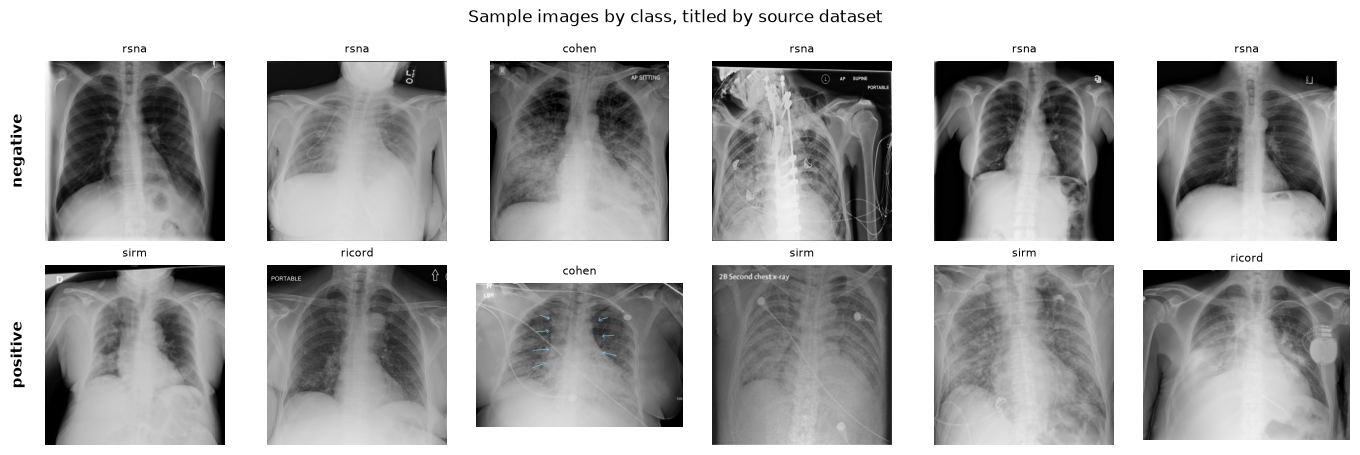

In [17]:
# actual images, a few per class, labeled with their source dataset
labels_present = train_df["class"].unique().tolist()
n_show = 6
fig, axes = plt.subplots(len(labels_present), n_show, figsize=(2.3 * n_show, 2.3 * len(labels_present)))
axes = np.atleast_2d(axes)

for row_idx, label in enumerate(labels_present):
    subset = train_df[train_df["class"] == label]
    subset = subset.sample(min(n_show, len(subset)), random_state=SEED)
    for col_idx, (_, row) in enumerate(subset.iterrows()):
        img = cv2.cvtColor(cv2.imread(covid_train_images / row["filename"]), cv2.COLOR_BGR2RGB)
        ax = axes[row_idx, col_idx]
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(row["data_source"], fontsize=8)

    axes[row_idx, 0].text(
        -0.15, 0.5, label, transform=axes[row_idx, 0].transAxes,
        rotation=90, va="center", ha="center", fontsize=11, fontweight="bold",
    )
fig.suptitle("Sample images by class, titled by source dataset")
plt.tight_layout()
plt.show()

## 4 PyTorch datasets and loaders

See 
- Model description: https://github.com/lindawangg/COVID-Net/blob/26c56cdc3ea79117517ccd73891246c0c075a1d9/docs/models.md
- Data preprocessing: https://github.com/lindawangg/COVID-Net/blob/26c56cdc3ea79117517ccd73891246c0c075a1d9/data.py

In [18]:
IMAGE_SIZE = 224
CLASSES = ["negative", "positive"]
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}

## 4.1. TorchVision image transforms

In [19]:
CropTop?

Init signature: CropTop(percent=0.08)
Docstring:      Crop the top `percent` of the image (X-rays often have embedded text/markers there).
File:           /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:           type
Subclasses:     

In [20]:
CenterSquareCrop?

Init signature: CenterSquareCrop()
Docstring:      Center-crop to a square of the smaller side.
File:           /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:           type
Subclasses:     

In [21]:
RandomRatioResize?

Init signature: RandomRatioResize(prob=0.3, delta=0.1, target_size=480)
Docstring:     
COVID-Net augmentation: with probability `prob`, distort the aspect ratio by
up to `delta`, then pad back out to a square `target_size` canvas.
File:           /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:           type
Subclasses:     

In [22]:
train_tf

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomHorizontalFlip(p=0.5)
    ColorJitter(brightness=(0.9, 1.1), contrast=None, saturation=None, hue=None)
    RandomAffine(degrees=[-10.0, 10.0], translate=(0.1, 0.1), scale=(0.85, 1.15))
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

In [23]:
eval_tf

Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

The PyTorch dataset would apply one of the above transformations depending on the task (train/valid/test)

In [24]:
COVIDxDataset?

Init signature:
COVIDxDataset(
    df,
    image_dir,
    transform,
    label_col='class',
    class_to_idx=None,
)
Docstring:     
Reads (path, label) pairs from a manifest dataframe. `label_col` and
`class_to_idx` let us reuse this exact class for the disease classifier
(label_col='class') and for the leakage probe (label_col='data_source').
File:           /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:           type
Subclasses:     

> **Implementation details**. The proposed COVID-Net was pretrained on the ImageNet dataset and then trained on the COVIDx dataset using the Adam optimizer using a learning rate policy where the learning rate decreases when learning stagnates for a period of time (i.e., ’patience’). The following hyperparameters were used  for training: `learning rate = 2e−4, number of epochs = 22, batch size = 64, factor = 0.7, patience = 5`. Finally, we introduce a batch re-balancing strategy to promote better distribution of each infection type at a batch level. The initial COVID-Net prototype was built and evaluated using the Keras deep learning library with a TensorFlow backend. The proposed COVID-Net architecture was built using generative synthesis, as described in “Machine-driven design exploration”.

In [25]:
from sklearn.model_selection import train_test_split

# NOTE: for small training set
# train_mini = train_df[~(train_df["data_source"].isin(("actmed","fig1")))].sample(600)

# NOTE: full training
train_mini = train_df
class_and_data_source = train_mini["class"].str.cat(train_mini["data_source"])

train_df_split, val_df_split = train_test_split(train_mini, test_size=0.1, random_state=SEED, shuffle=True, stratify=class_and_data_source)

In [26]:
print(train_df_split["class"].value_counts())
print()
print(train_df_split["data_source"].value_counts())

class
negative    12412
positive     1943
Name: count, dtype: int64

data_source
rsna      12049
sirm        849
ricord      806
cohen       510
actmed      119
fig1         22
Name: count, dtype: int64


In [27]:
print(val_df_split["class"].value_counts())
print()
print(val_df_split["data_source"].value_counts())

class
negative    1380
positive     215
Name: count, dtype: int64

data_source
rsna      1339
sirm        94
ricord      90
cohen       57
actmed      13
fig1         2
Name: count, dtype: int64


In [28]:
BATCH_SIZE = 256  # Decrease if memory is limited. For example 32 = fits in 3GB VRAM

train_ds = COVIDxDataset(train_df_split.drop(columns=["data_source"]), covid_train_images, train_tf)
val_ds = COVIDxDataset(val_df_split.drop(columns=["data_source"]), covid_train_images, eval_tf)
test_ds = COVIDxDataset(test_df, covid_test_images, eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False)

## 5. Model: transfer learning on a pretrained CNN

A ResNet-50 with an ImageNet-pretrained backbone and a fresh 2-way head - a fairly typical setup for the 2020-era COVID-X-ray papers this notebook is stress-testing.

In [29]:
torchvision.models.resnet50?

Signature:
torchvision.models.resnet50(
    *,
    weights: Optional[torchvision.models.resnet.ResNet50_Weights] = None,
    progress: bool = True,
    **kwargs: Any,
) -> torchvision.models.resnet.ResNet
Docstring:
ResNet-50 from `Deep Residual Learning for Image Recognition <https://arxiv.org/abs/1512.03385>`__.

.. note::
   The bottleneck of TorchVision places the stride for downsampling to the second 3x3
   convolution while the original paper places it to the first 1x1 convolution.
   This variant improves the accuracy and is known as `ResNet V1.5
   <https://ngc.nvidia.com/catalog/model-scripts/nvidia:resnet_50_v1_5_for_pytorch>`_.

Args:
    weights (:class:`~torchvision.models.ResNet50_Weights`, optional): The
        pretrained weights to use. See
        :class:`~torchvision.models.ResNet50_Weights` below for
        more details, and possible values. By default, no pre-trained
        weights are used.
    progress (bool, optional): If True, displays a progress bar of the
 

In [30]:
def build_model():
    model = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1)
    model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
    return model.to(DEVICE)

In [31]:
train_epoch?

Signature: train_epoch(model, loader, optimizer, criterion, use_bce=False)
Docstring: One pass over the training loader: forward, backward, optimizer step.
File:      /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:      function

In [32]:
eval_epoch?

Signature: eval_epoch(model, loader, criterion, use_bce=False)
Docstring: One pass over an eval loader: mean loss and accuracy.
File:      /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:      function

In [33]:
train_model?

Signature:
train_model(
    model,
    optimizer,
    train_loader,
    val_loader,
    history,
    n_epochs=22,
    patience=5,
    epoch_start=0,
    use_bce=False,
)
Docstring: Training loop.
File:      /pfs/lustrep4/scratch/project_465002387/mohanana/xai-for-life-science-dev/chest_xray/utils_covidx.py
Type:      function

In [34]:
disease_model = build_model()

In [35]:
optimizer = torch.optim.Adam(disease_model.parameters(), lr=2e-4)
history = {
    "train_loss": [], "val_loss": [], "val_acc": []
}
epoch = train_model(
    disease_model, optimizer, train_loader, val_loader, history,
    n_epochs=22, use_bce=True
)

train:   0%|          | 0/57 [00:00<?, ?it/s]

eval:   0%|          | 0/7 [00:00<?, ?it/s]

epoch 1/22  train_loss=0.1686  val_loss=0.0973  val_acc=0.9730


train:   0%|          | 0/57 [00:00<?, ?it/s]

eval:   0%|          | 0/7 [00:00<?, ?it/s]

...

epoch 8/22  train_loss=0.0730  val_loss=0.0681  val_acc=0.9799


train:   0%|          | 0/57 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x14de1cd7fec0>
Traceback (most recent call last):
  File "/opt/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/opt/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x14de1cd7fec0>
Traceback (most recent call last):
  File "/opt/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/opt/venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py", line 1692, 

eval:   0%|          | 0/7 [00:00<?, ?it/s]

epoch 9/22  train_loss=0.0560  val_loss=0.0639  val_acc=0.9749
early stopping at epoch 9: no val_loss improvement for 5 epochs


In [36]:
trained_model_path = "disease_model_checkpoint.pth"
torch.save(
    {
        'epoch': epoch,
        'model_state_dict': disease_model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'history': history,
    }, 
    trained_model_path
)

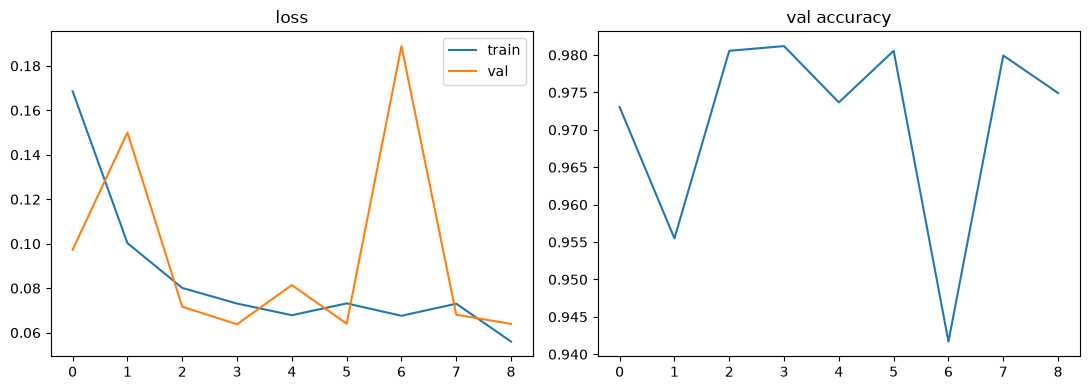

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("loss"); axes[0].legend()
axes[1].plot(history["val_acc"])
axes[1].set_title("val accuracy")
plt.tight_layout(); plt.show()

## 6. Evaluate the disease classifier on the held-out test set

In [38]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    all_probs, all_labels = [], []
    for x, y in loader:
        x = x.to(DEVICE)
        probs = torch.softmax(model(x), dim=1)[:, CLASS_TO_IDX["positive"]].cpu().numpy()
        all_probs.append(probs)
        all_labels.append(y.numpy())
    return np.concatenate(all_probs), np.concatenate(all_labels)


test_probs, test_labels = predict(disease_model, test_loader)
test_preds = (test_probs >= 0.5).astype(int)

print("accuracy:", accuracy_score(test_labels, test_preds))
print("AUC:", roc_auc_score(test_labels, test_probs))
print(classification_report(test_labels, test_preds, target_names=CLASSES))
print("confusion matrix:\n", confusion_matrix(test_labels, test_preds))

accuracy: 0.855
AUC: 0.991725
              precision    recall  f1-score   support

    negative       0.78      1.00      0.87       200
    positive       1.00      0.71      0.83       200

    accuracy                           0.85       400
   macro avg       0.89      0.85      0.85       400
weighted avg       0.89      0.85      0.85       400

confusion matrix:
 [[200   0]
 [ 58 142]]


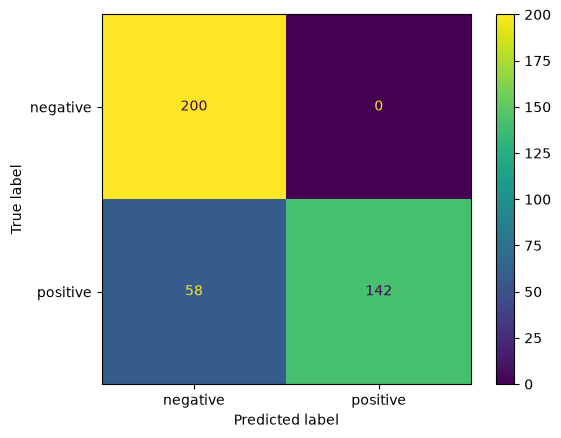

In [40]:
from sklearn.metrics import ConfusionMatrixDisplay


disp = ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(test_labels, test_preds),
                              display_labels=CLASSES)

disp.plot()

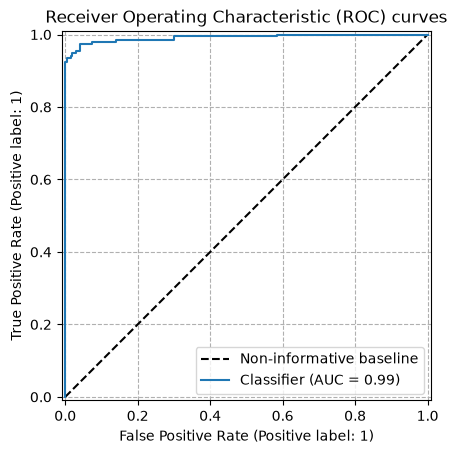

In [43]:
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots()


ax.grid(linestyle="--")
ax.set_title("Receiver Operating Characteristic (ROC) curves")
baseline = np.linspace(0, 1)
ax.plot(baseline, baseline, color="black", linestyle="--", label="Non-informative baseline")
RocCurveDisplay.from_predictions(test_labels, test_probs, ax=ax)
ax.legend()

If accuracy/AUC here look almost too good (they usually do, on this kind of dataset), that is the cue to move on to the XAI audit rather than declare victory - exactly the situation DataRobot's post is describing.